<a href="https://colab.research.google.com/github/rhmau1/PCVK_26/blob/main/Modul7/Modul7_D1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 - Segmentasi Citra dengan Thresholding
**Pengolahan Citra dan Visi Komputer - Modul P7**
**Bagian: D1. Tugas Individu (No. 1-7)**

Isi notebook:
1. Persiapan (mount Drive, library, path)
2. Global Threshold manual (threshold = 200)
3. Adaptive Threshold manual (mean & Gaussian) pada citra Sudoku
4. Otsu manual (Lena + KTP) beserta jawaban pertanyaan
5. Region-based segmentation (Region Growing manual + `flood()`)
6. Segmentasi warna K-Means pada KTP (hanya warna biru)

## 1. Persiapan
Mount Google Drive, lalu import library.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Import library

In [2]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans   # dipakai pada soal no. 7

### Path file
Perhatikan: pada path folder terdapat **spasi setelah kata `RESOURCES`** (`TI 3C RESOURCES /PCVK/...`), sesuai path yang Anda berikan.
Gambar lain (gradient, sudoku, lena) diasumsikan berada di folder yang sama dengan `ktp_fulan.jpg`. Ubah di sini jika berbeda.

In [3]:
import os

BASE = '/content/drive/MyDrive/TI 3C RESOURCES /PCVK/Images/'

PATH_GRADIENT = BASE + 'gradient.jpg'
PATH_SUDOKU   = BASE + 'sudoku-original.jpg'
PATH_LENA     = BASE + 'lena_gs_lc2.jpg'
PATH_KTP      = BASE + 'ktp_fulan.jpg'

for p in [PATH_GRADIENT, PATH_SUDOKU, PATH_LENA, PATH_KTP]:
    print('ADA        ' if os.path.exists(p) else 'TIDAK ADA  ', p)

def load_gray(path, fallback=None):
    # Baca citra sebagai grayscale
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if img is None:
        if fallback is None:
            raise FileNotFoundError('File tidak ditemukan: ' + path)
        print('File tidak ditemukan, memakai citra pengganti:', path)
        return fallback
    return img

ADA         /content/drive/MyDrive/TI 3C RESOURCES /PCVK/Images/gradient.jpg
ADA         /content/drive/MyDrive/TI 3C RESOURCES /PCVK/Images/sudoku-original.jpg
ADA         /content/drive/MyDrive/TI 3C RESOURCES /PCVK/Images/lena_gs_lc2.jpg
ADA         /content/drive/MyDrive/TI 3C RESOURCES /PCVK/Images/ktp_fulan.jpg


## 2. Global Threshold secara manual (threshold = 200)
Hanya memakai NumPy (tanpa `cv.threshold`). Aturan sesuai tabel pada soal:

| Jenis | piksel > thresh | piksel <= thresh |
|---|---|---|
| BINARY | nilai maksimal | 0 |
| BINARY_INV | 0 | nilai maksimal |
| TRUNC | thresh | nilai asli |
| TOZERO | nilai asli | 0 |
| TOZERO_INV | 0 | nilai asli |

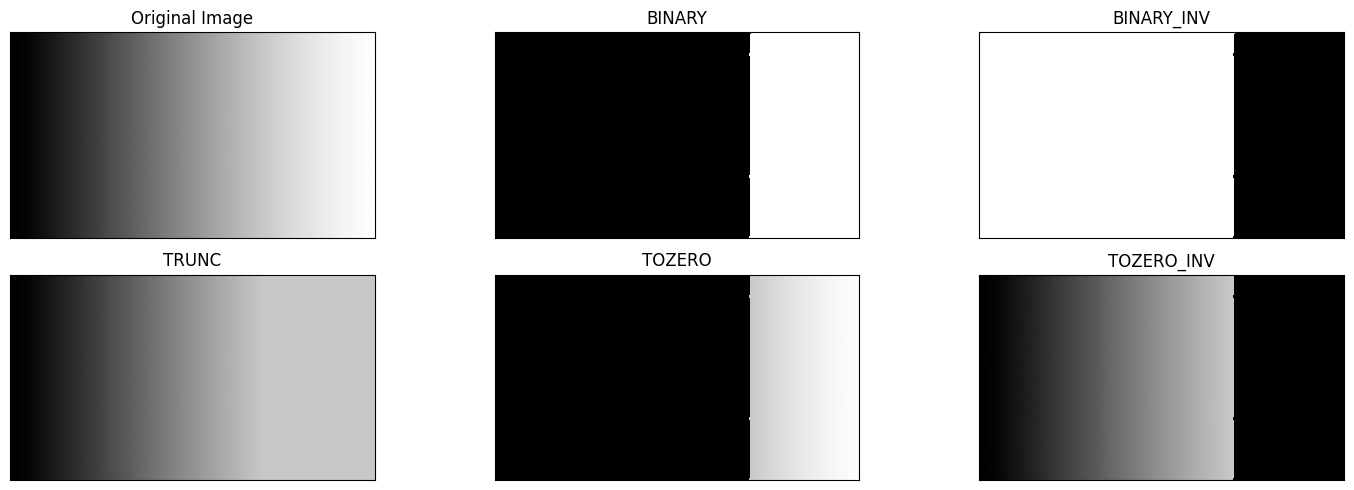

In [4]:
THRESH = 200
MAXVAL = 255

# Jika gradient.jpg tidak ada, dibuat gradasi hitam-putih sebagai pengganti
gradasi_pengganti = np.tile(np.linspace(0, 255, 512).astype(np.uint8), (256, 1))
img_grad = load_gray(PATH_GRADIENT, gradasi_pengganti)

def th_binary(img, t, maxval=255):
    return np.where(img > t, maxval, 0).astype(np.uint8)

def th_binary_inv(img, t, maxval=255):
    return np.where(img > t, 0, maxval).astype(np.uint8)

def th_trunc(img, t):
    return np.where(img > t, t, img).astype(np.uint8)

def th_tozero(img, t):
    return np.where(img > t, img, 0).astype(np.uint8)

def th_tozero_inv(img, t):
    return np.where(img > t, 0, img).astype(np.uint8)

hasil_global = [
    img_grad,
    th_binary(img_grad, THRESH, MAXVAL),
    th_binary_inv(img_grad, THRESH, MAXVAL),
    th_trunc(img_grad, THRESH),
    th_tozero(img_grad, THRESH),
    th_tozero_inv(img_grad, THRESH),
]
judul_global = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']

plt.figure(figsize=(15, 5))
for i in range(len(hasil_global)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(hasil_global[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(judul_global[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

Verifikasi: hasil manual dibandingkan dengan fungsi OpenCV (hanya untuk mengecek kebenaran, bukan untuk membuat hasil).

In [5]:
ref = {
    'BINARY':     cv.threshold(img_grad, THRESH, MAXVAL, cv.THRESH_BINARY)[1],
    'BINARY_INV': cv.threshold(img_grad, THRESH, MAXVAL, cv.THRESH_BINARY_INV)[1],
    'TRUNC':      cv.threshold(img_grad, THRESH, MAXVAL, cv.THRESH_TRUNC)[1],
    'TOZERO':     cv.threshold(img_grad, THRESH, MAXVAL, cv.THRESH_TOZERO)[1],
    'TOZERO_INV': cv.threshold(img_grad, THRESH, MAXVAL, cv.THRESH_TOZERO_INV)[1],
}
for nama, hasil in zip(judul_global[1:], hasil_global[1:]):
    print(f'{nama:11s} sama dengan OpenCV:', np.array_equal(hasil, ref[nama]))

BINARY      sama dengan OpenCV: True
BINARY_INV  sama dengan OpenCV: True
TRUNC       sama dengan OpenCV: True
TOZERO      sama dengan OpenCV: True
TOZERO_INV  sama dengan OpenCV: True


## 3. Adaptive Threshold manual (mean & Gaussian) pada citra Sudoku
Tanpa `cv.threshold()`, `cv.adaptiveThreshold()`, maupun fungsi filter siap pakai (`cv.blur`, `GaussianBlur`, `ndi.uniform_filter`, dst).

Ketentuan: global threshold manual T = 127, jendela 11 x 11, C = 2, sigma = 2 (Gaussian).

- **Rata-rata lokal** dihitung dengan *integral image* (cumulative sum), jadi cepat.
- **Rata-rata Gaussian** dihitung dengan konvolusi terpisah (separable) memakai kernel Gaussian 1D yang dibuat sendiri.
- Ambang lokal: `T(x, y) = rata-rata - C`, lalu `piksel > T(x, y)` menjadi putih (255), selain itu hitam (0).
- Tepi citra diperlakukan dengan replikasi piksel tepi (`np.pad(mode='edge')`).

In [6]:
def mean_lokal(gray, b):
    # Rata-rata jendela b x b memakai integral image
    pad = b // 2
    g = np.pad(gray.astype(np.float64), pad, mode='edge')
    ii = np.cumsum(np.cumsum(g, axis=0), axis=1)
    ii = np.pad(ii, ((1, 0), (1, 0)))           # baris & kolom nol di awal
    H, W = gray.shape
    jumlah = (ii[b:b + H, b:b + W] - ii[0:H, b:b + W]
              - ii[b:b + H, 0:W] + ii[0:H, 0:W])
    return jumlah / (b * b)

def kernel_gauss_1d(b, sigma):
    ax = np.arange(b) - b // 2
    k = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    return k / k.sum()

def gauss_lokal(gray, b, sigma):
    # Rata-rata berbobot Gaussian (konvolusi separable: horizontal lalu vertikal)
    k = kernel_gauss_1d(b, sigma)
    pad = b // 2
    H, W = gray.shape
    g = np.pad(gray.astype(np.float64), pad, mode='edge')
    tmp = np.zeros((H + 2 * pad, W))
    for i in range(b):
        tmp += k[i] * g[:, i:i + W]
    out = np.zeros((H, W))
    for i in range(b):
        out += k[i] * tmp[i:i + H, :]
    return out

def global_manual(gray, t=127):
    return np.where(gray > t, 255, 0).astype(np.uint8)

def adaptive_manual(gray, metode='mean', b=11, C=2, sigma=2):
    if metode == 'mean':
        lokal = mean_lokal(gray, b)
    elif metode == 'gaussian':
        lokal = gauss_lokal(gray, b, sigma)
    else:
        raise ValueError("metode harus 'mean' atau 'gaussian'")
    T = lokal - C                       # ambang lokal T(x, y)
    return np.where(gray > T, 255, 0).astype(np.uint8)

def median_manual(gray, k=5):
    # Opsional (modul memakai medianBlur 5); ditulis manual agar tetap memenuhi ketentuan
    pad = k // 2
    H, W = gray.shape
    g = np.pad(gray, pad, mode='edge')
    tumpukan = [g[dy:dy + H, dx:dx + W] for dy in range(k) for dx in range(k)]
    return np.median(np.stack(tumpukan), axis=0).astype(np.uint8)

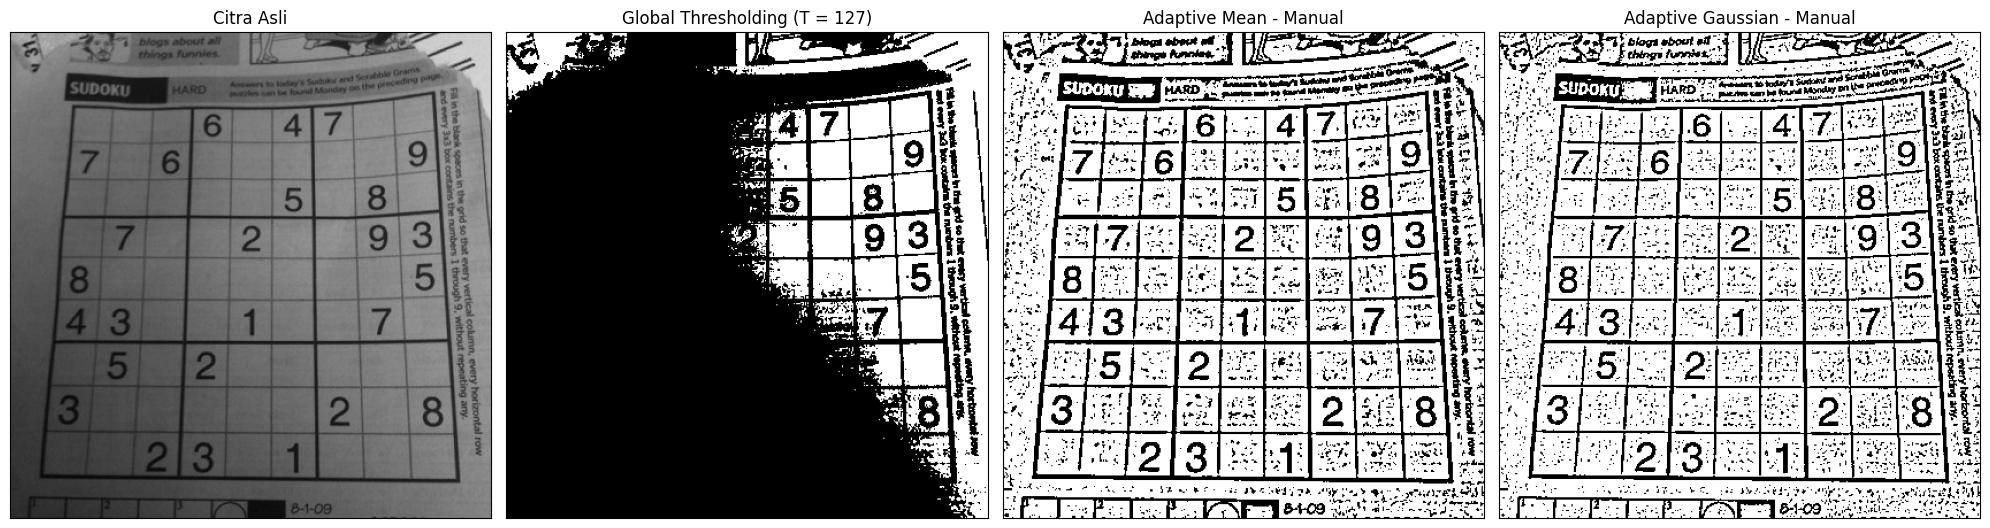

In [7]:
gray_sudoku = load_gray(PATH_SUDOKU)

PAKAI_MEDIAN = False      # ubah True jika ingin pra-proses median 5x5 seperti contoh modul
if PAKAI_MEDIAN:
    gray_sudoku = median_manual(gray_sudoku, 5)

th_global   = global_manual(gray_sudoku, 127)
th_adp_mean = adaptive_manual(gray_sudoku, 'mean',     b=11, C=2)
th_adp_gaus = adaptive_manual(gray_sudoku, 'gaussian', b=11, C=2, sigma=2)

hasil_sudoku = [gray_sudoku, th_global, th_adp_mean, th_adp_gaus]
judul_sudoku = ['Citra Asli', 'Global Thresholding (T = 127)',
                'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']

plt.figure(figsize=(20, 6))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(hasil_sudoku[i], 'gray', vmin=0, vmax=255)
    plt.title(judul_sudoku[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Catatan:** global threshold gagal pada bagian gelap (bayangan) karena satu nilai T tidak cocok untuk seluruh citra, sedangkan adaptive threshold menghitung ambang untuk tiap piksel dari lingkungannya sehingga angka sudoku tetap terbaca.

## 4. Otsu Thresholding tanpa library
### 4A. Citra `lena_gs_lc2.jpg`
Algoritma: untuk setiap kandidat T (0..254), piksel <= T = background dan piksel > T = foreground. Pilih T yang **memaksimalkan between-class variance**:

`sigma_B^2(T) = w0(T) * w1(T) * (mu0(T) - mu1(T))^2`

(ekuivalen dengan meminimalkan within-class variance).

/tmp/ipykernel_4863/101051513.py:17: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_4863/101051513.py:18: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


93


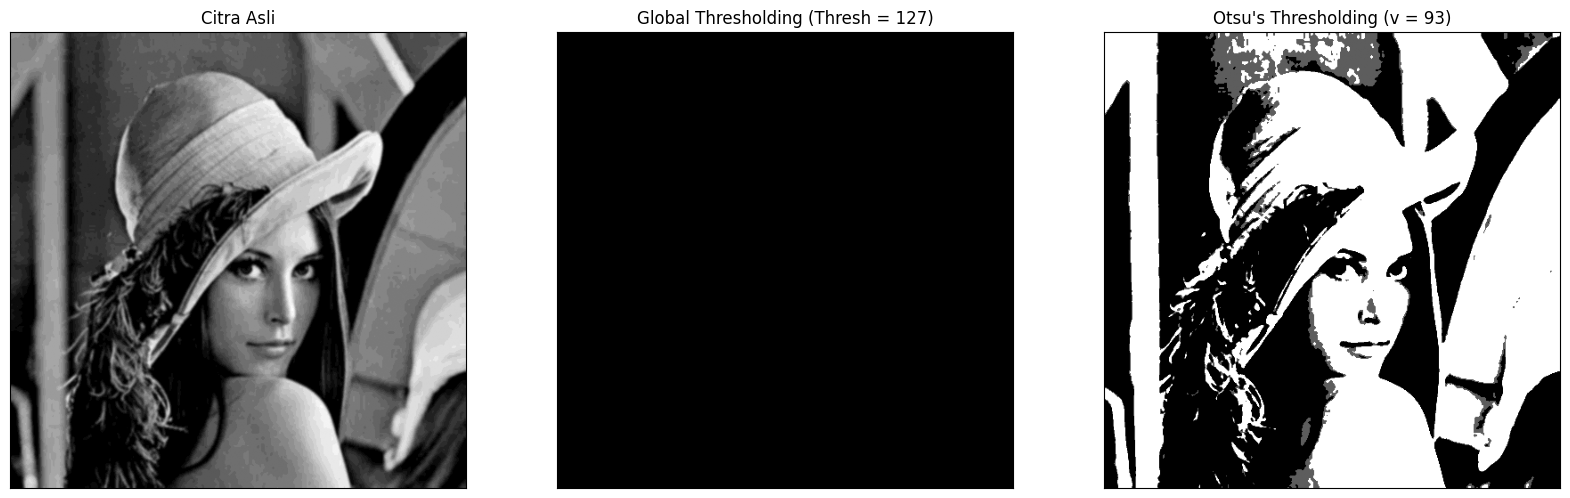

In [22]:
gray_lena = load_gray(PATH_LENA)

blur_lena = cv.GaussianBlur(gray_lena,(5,5),0)
thresh=127
def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight
    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2
    if value > final_value:
      final_thresh = t
      final_value = value
  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh
otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]
plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

> Catatan: kode contoh pada modul memakai bin `t` sebagai batas *eksklusif* (piksel < t = background), sehingga nilai yang tercetak bisa lebih besar 1 dari `cv.THRESH_OTSU` (contoh modul: 93 vs 92). Pada implementasi di atas, batasnya inklusif (piksel <= T = background) sehingga nilainya sama dengan OpenCV.

### Pertanyaan: mengapa Binary Thresholding (T = 127) hasilnya hitam semua?

Intensitas minimum : 85
Intensitas maksimum: 108
Rentang intensitas : 24 level
Piksel > 127       : 0 dari 262144


/tmp/ipykernel_4863/2898826828.py:7: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur_lena.ravel(), 256, [0, 256], color='steelblue')


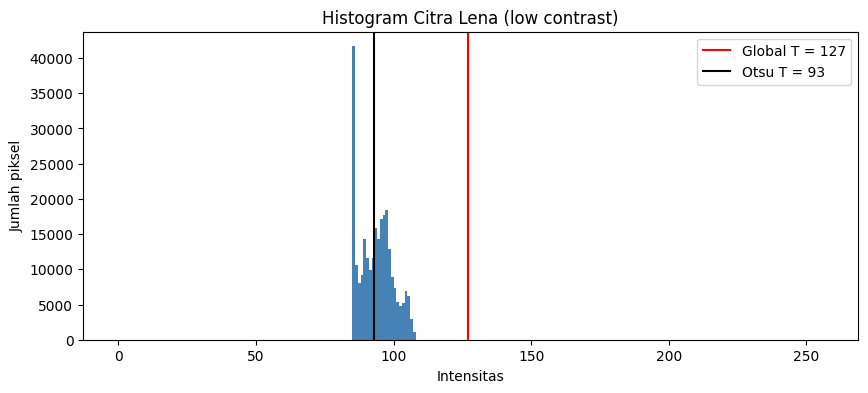


Thresh | % piksel putih | keterangan
    60 |        100.00% | semua putih
    85 |         84.11% | objek terlihat
    90 |         63.56% | objek terlihat
    93 |         49.29% | objek terlihat
   100 |         12.40% | objek terlihat
   107 |          0.01% | objek terlihat
   108 |          0.00% | semua hitam
   127 |          0.00% | semua hitam


In [23]:
print('Intensitas minimum :', blur_lena.min())
print('Intensitas maksimum:', blur_lena.max())
print('Rentang intensitas :', blur_lena.max() - blur_lena.min() + 1, 'level')
print('Piksel > 127       :', int((blur_lena > 127).sum()), 'dari', blur_lena.size)

plt.figure(figsize=(10, 4))
plt.hist(blur_lena.ravel(), 256, [0, 256], color='steelblue')
plt.axvline(127, color='red', label='Global T = 127')
plt.axvline(otsu_thresh, color='black', label=f'Otsu T = {otsu_thresh}')
plt.title('Histogram Citra Lena (low contrast)')
plt.xlabel('Intensitas'); plt.ylabel('Jumlah piksel')
plt.legend()
plt.show()

# Uji beberapa nilai ambang: berapa % piksel yang menjadi putih?
print('\nThresh | % piksel putih | keterangan')
for t in [60, blur_lena.min(), 90, otsu_thresh, 100, blur_lena.max() - 1, blur_lena.max(), 127]:
    persen = 100 * (blur_lena > t).mean()
    ket = 'semua hitam' if persen == 0 else ('semua putih' if persen == 100 else 'objek terlihat')
    print(f'{int(t):6d} | {persen:13.2f}% | {ket}')

**Jawaban:**

Citra `lena_gs_lc2.jpg` adalah citra *low contrast*: seluruh intensitasnya hanya terkumpul pada rentang sempit (sekitar **85-108**, lihat nilai minimum/maksimum yang dicetak di atas), sehingga pada histogram semua batang berada di **sebelah kiri garis merah T = 127**.

Aturan Binary Threshold adalah `dst = 255` jika `src > T`, selain itu `0`. Karena tidak ada satu pun piksel yang nilainya lebih besar dari 127, semua piksel memenuhi kondisi `src <= T` dan menjadi **0 (hitam)**.

Agar Lena masih terlihat, nilai threshold harus berada di dalam rentang intensitas citra, yaitu **minimum <= T < maksimum** (sekitar **85 <= T < 108**; pastikan dengan angka yang dicetak sel di atas). Nilai yang paling baik adalah yang memisahkan dua kelompok pada histogram, yaitu hasil Otsu (**sekitar 92-93**), karena Otsu menghitung T langsung dari histogram.

### 4B. Citra KTP sendiri (`ktp_fulan.jpg`)
Membandingkan global threshold biasa (T = 127) dengan Otsu manual.

151


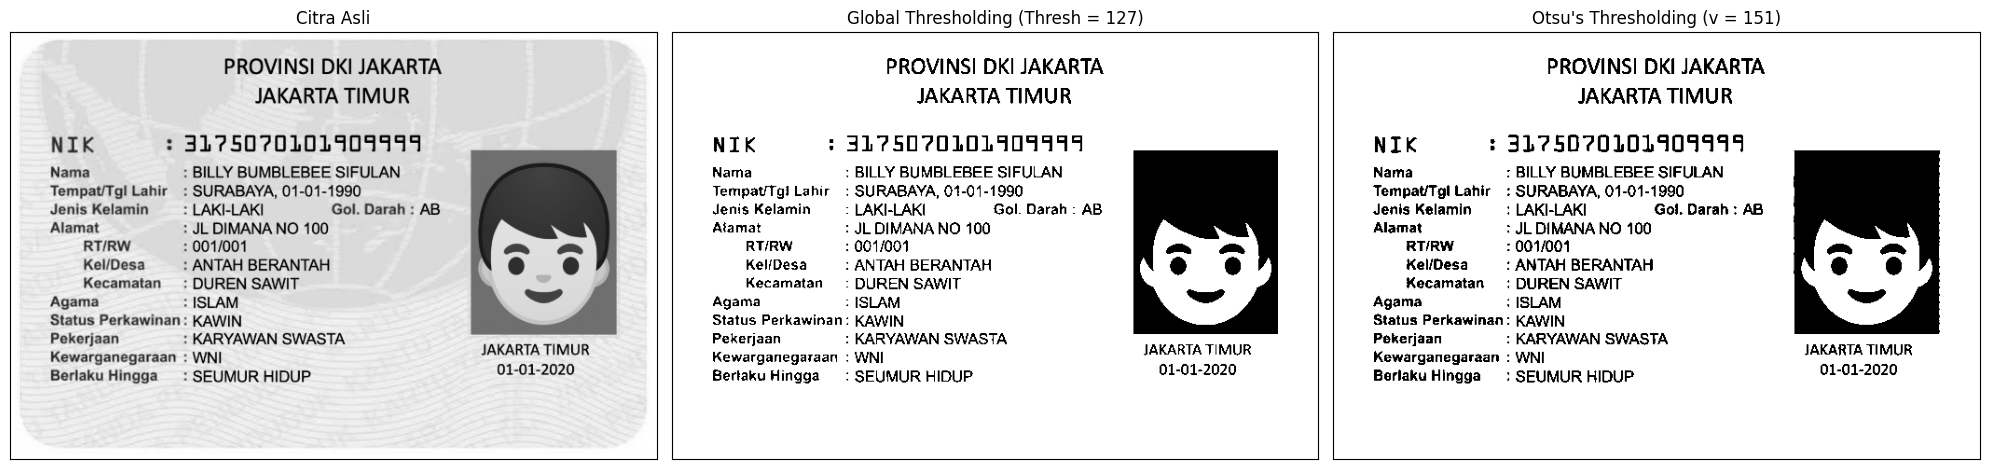

Threshold Otsu pada KTP: 151


In [25]:
gray_ktp = load_gray(PATH_KTP)

otsu_ktp, t_otsu_ktp = otsu(gray_ktp)
global_ktp = global_manual(gray_ktp, 127)

hasil_ktp = [gray_ktp, global_ktp, otsu_ktp]
judul_ktp = ['Citra Asli', 'Global Thresholding (Thresh = 127)',
             "Otsu's Thresholding (v = " + str(t_otsu_ktp) + ")"]

plt.figure(figsize=(20, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(hasil_ktp[i], 'gray', vmin=0, vmax=255)
    plt.title(judul_ktp[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

print('Threshold Otsu pada KTP:', t_otsu_ktp)

**Pembahasan singkat:** KTP memiliki latar biru muda yang terang dengan tulisan gelap. Global threshold 127 adalah nilai tetap yang belum tentu cocok dengan sebaran intensitas KTP, sedangkan Otsu memilih T dari histogram sehingga memisahkan tulisan (gelap) dari latar (terang) secara otomatis. Bandingkan kedua hasil di atas: perhatikan apakah tulisan kecil masih utuh dan apakah latar bersih.

## 5. Segmentasi Berbasis Region pada `data.coins()`
### 5A. Region Growing manual
- Region dimulai dari **seed**, lalu meluas ke tetangga (4 ketetanggaan) yang memenuhi kriteria kesamaan `|I(q) - mean_region| < T`.
- 3 seed: **di dalam koin**, **di latar**, dan **tepat di tepi koin**.
- Dijalankan dengan T = 5, 20, dan 60, ditampilkan dalam grid 3 x 3 (seed x T).

In [11]:
coins = data.coins()          # grayscale, 303 x 384
print('Ukuran citra coins:', coins.shape, '| dtype:', coins.dtype)

def region_growing(gray, seed, T):
    # Region growing dengan 4 ketetanggaan; kriteria: |I(q) - rata-rata region| < T
    H, W = gray.shape
    mask = np.zeros((H, W), dtype=bool)
    r, c = seed
    mask[r, c] = True
    jumlah = float(gray[r, c])      # jumlah intensitas anggota region
    n = 1                           # banyak anggota region
    antrean = deque([(r, c)])
    tetangga = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    while antrean:
        y, x = antrean.popleft()
        for dy, dx in tetangga:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx]:
                if abs(float(gray[ny, nx]) - jumlah / n) < T:
                    mask[ny, nx] = True
                    jumlah += float(gray[ny, nx])
                    n += 1
                    antrean.append((ny, nx))
    return mask

Ukuran citra coins: (303, 384) | dtype: uint8


**Penentuan seed.** Seed koin memakai (36, 43) seperti pada contoh modul. Seed latar diambil dari pojok kiri atas, dan seed tepi koin dicari otomatis: dari titik tengah koin bergerak ke kanan dan dipilih posisi dengan perubahan intensitas terbesar (batas koin-latar). Silakan ubah manual bila perlu; nilai intensitas tiap seed dicetak agar mudah dicek.

In [12]:
def cari_tepi_koin(gray, seed_dalam, jarak_maks=40):
    # Cari piksel pada tepi koin: gradien terbesar ke arah kanan dari seed di dalam koin
    r, c = seed_dalam
    garis = gray[r, c:c + jarak_maks].astype(float)
    gradien = np.abs(np.diff(garis))
    return (r, c + int(np.argmax(gradien)))

seed_koin  = (36, 43)
seed_latar = (5, 5)
seed_tepi  = cari_tepi_koin(coins, seed_koin)

SEEDS = {'Seed di dalam koin': seed_koin,
         'Seed di latar': seed_latar,
         'Seed di tepi koin': seed_tepi}

for nama, s in SEEDS.items():
    print(f'{nama:20s} (baris, kolom) = {s} | intensitas = {coins[s]}')

T_LIST = [5, 20, 60]

Seed di dalam koin   (baris, kolom) = (36, 43) | intensitas = 159
Seed di latar        (baris, kolom) = (5, 5) | intensitas = 133
Seed di tepi koin    (baris, kolom) = (36, 52) | intensitas = 144


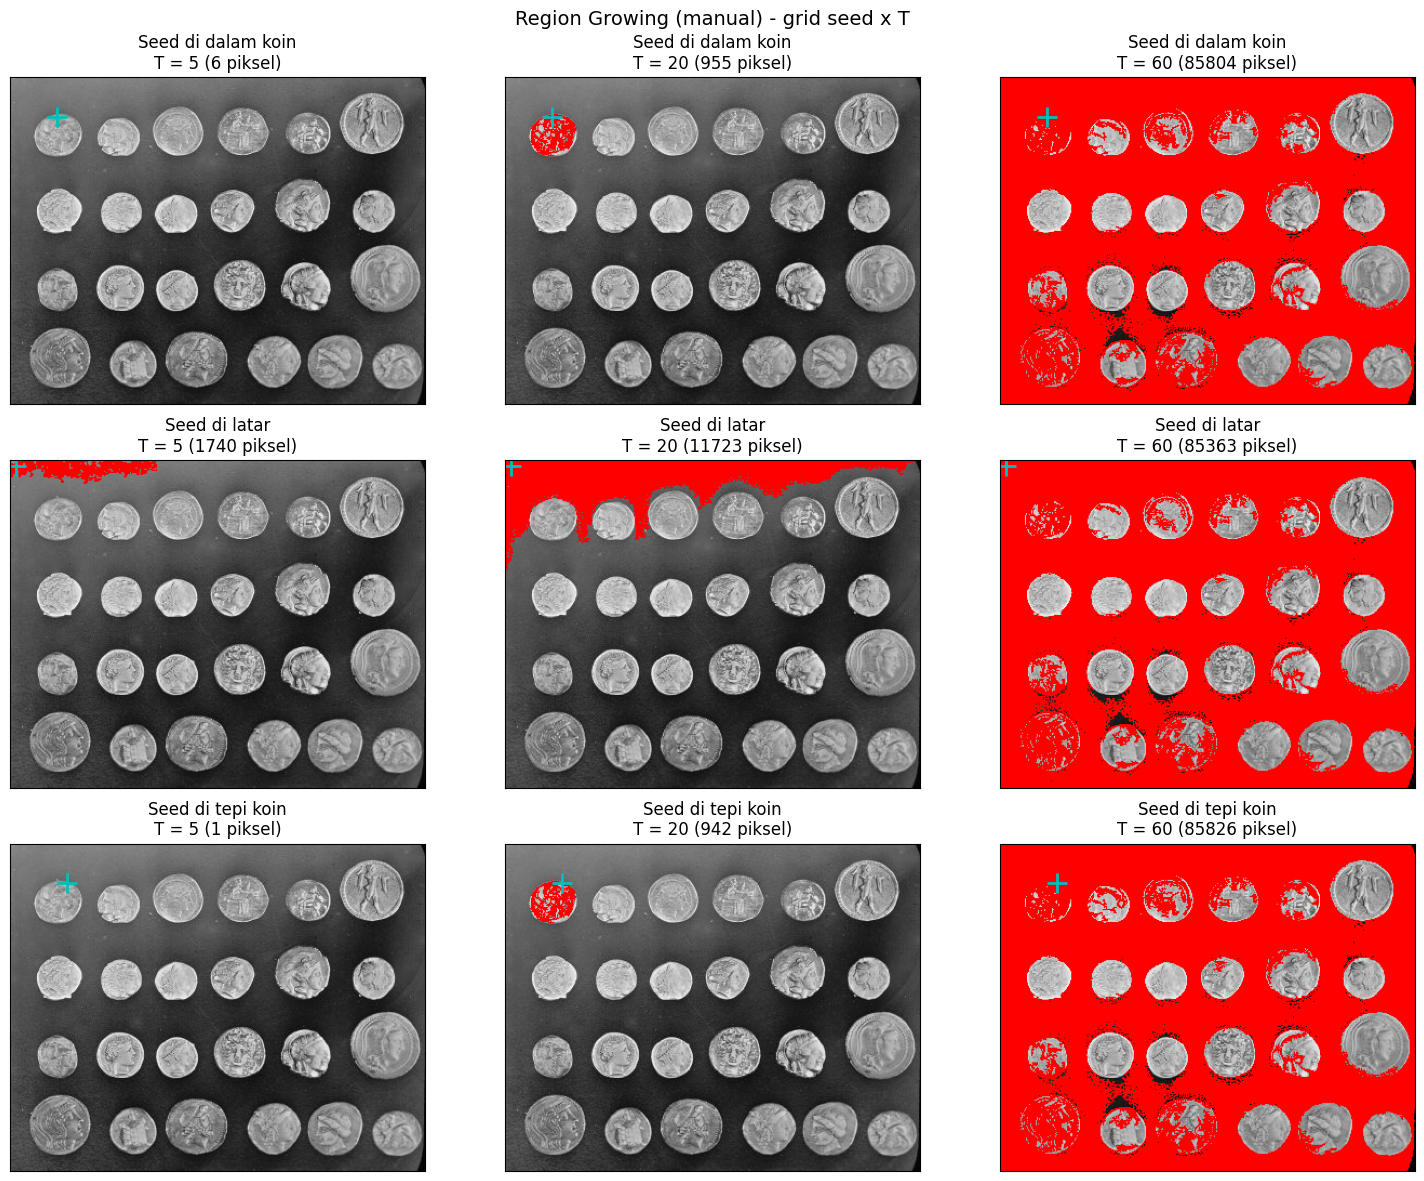

In [13]:
def tampilkan_grid(fungsi_segmentasi, judul_utama):
    jumlah = {}
    fig, axes = plt.subplots(len(SEEDS), len(T_LIST), figsize=(15, 12))
    for i, (nama, s) in enumerate(SEEDS.items()):
        for j, T in enumerate(T_LIST):
            mask = fungsi_segmentasi(coins, s, T)
            jumlah[(nama, T)] = int(mask.sum())
            overlay = np.dstack([coins] * 3).copy()
            overlay[mask] = [255, 0, 0]               # region berwarna merah
            ax = axes[i, j]
            ax.imshow(overlay)
            ax.plot(s[1], s[0], 'c+', markersize=14, markeredgewidth=2)   # tanda seed
            ax.set_title(f'{nama}\nT = {T} ({jumlah[(nama, T)]} piksel)')
            ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(judul_utama, fontsize=14)
    plt.tight_layout()
    plt.show()
    return jumlah

jumlah_manual = tampilkan_grid(region_growing, 'Region Growing (manual) - grid seed x T')

### 5B. Dengan `skimage.segmentation.flood()`
Fungsi ini menghasilkan mask region dari seed dengan menerima piksel yang **terhubung** dan intensitasnya berada dalam **toleransi terhadap intensitas seed**. `connectivity=1` berarti 4 tetangga untuk citra 2D.

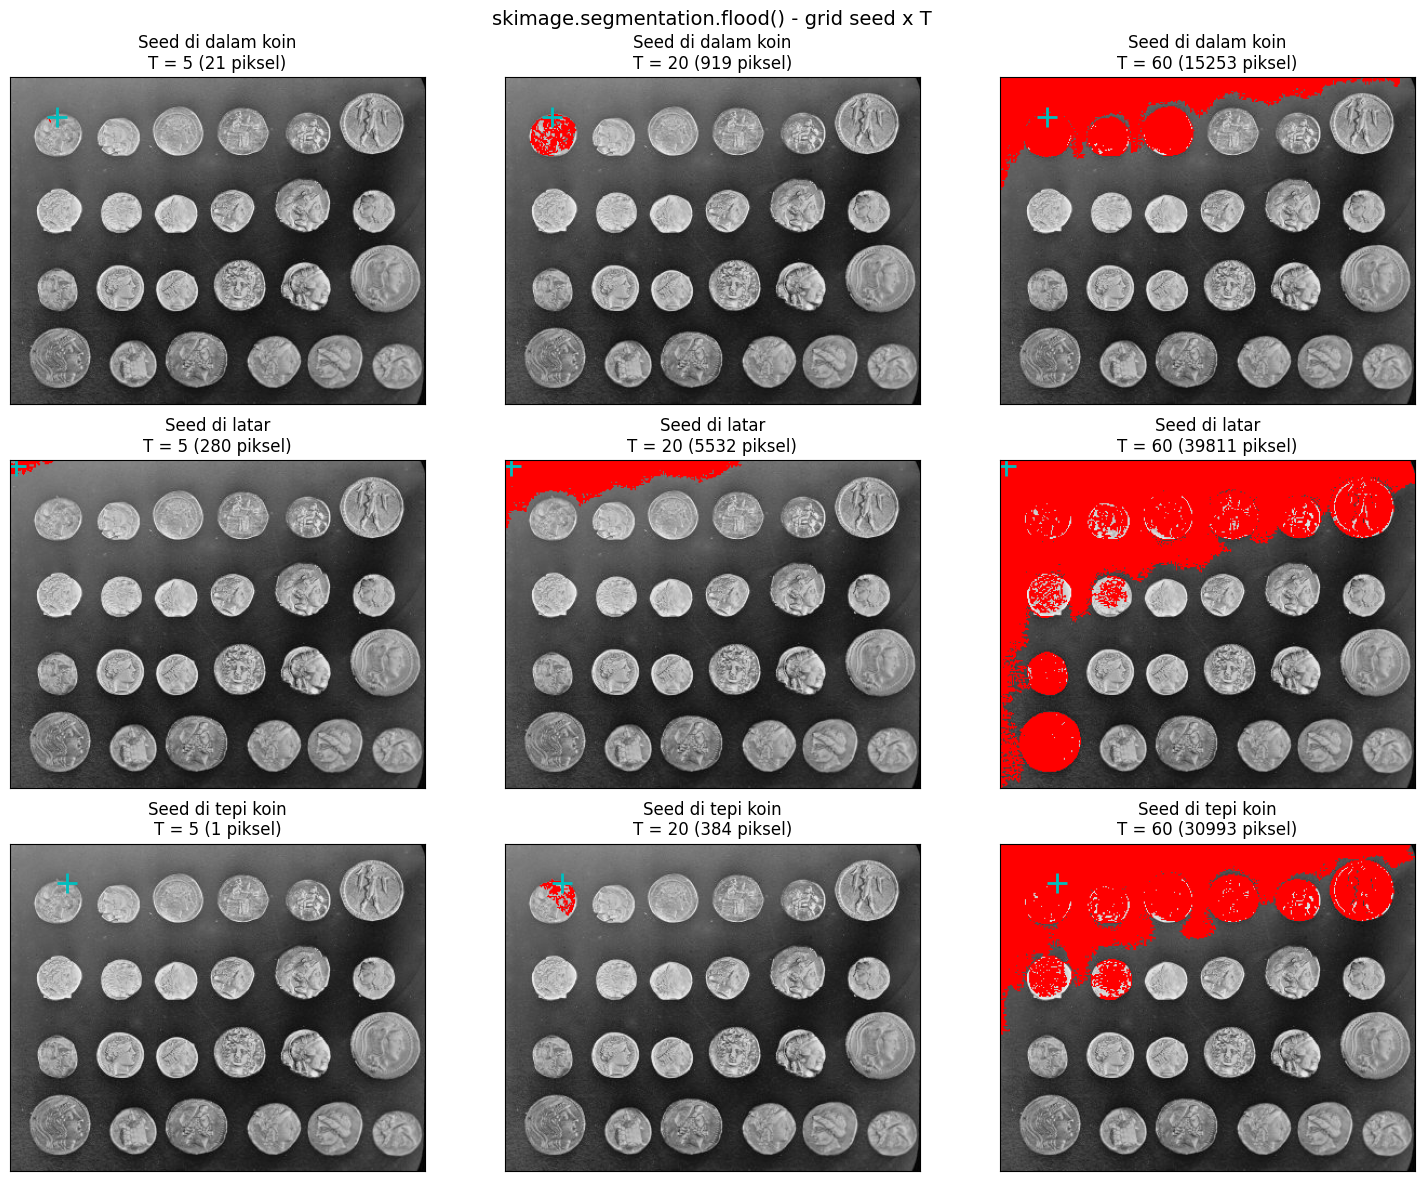

In [14]:
def region_flood(gray, seed, T):
    return flood(gray, seed_point=seed, tolerance=T, connectivity=1)

jumlah_flood = tampilkan_grid(region_flood, 'skimage.segmentation.flood() - grid seed x T')

In [15]:
# Perbandingan jumlah piksel region: manual vs flood()
baris = []
for nama in SEEDS:
    for T in T_LIST:
        baris.append({'Seed': nama, 'T': T,
                      'Region Growing manual': jumlah_manual[(nama, T)],
                      'flood()': jumlah_flood[(nama, T)]})
df_banding = pd.DataFrame(baris)
df_banding

,Seed,T,Region Growing manual,flood()
0,Seed di dalam koin,5,6,21
1,Seed di dalam koin,20,955,919
2,Seed di dalam koin,60,85804,15253
3,Seed di latar,5,1740,280
4,Seed di latar,20,11723,5532
5,Seed di latar,60,85363,39811
6,Seed di tepi koin,5,1,1
7,Seed di tepi koin,20,942,384
8,Seed di tepi koin,60,85826,30993


**Catatan:** jumlah piksel manual dan `flood()` tidak harus sama karena kriterianya berbeda. Region Growing manual membandingkan piksel dengan **rata-rata region yang terus berubah**, sedangkan `flood()` membandingkan dengan **intensitas seed saja** (seed +/- tolerance). Pengamatan umum: T kecil membuat region hanya berupa bercak di sekitar seed, T sedang (20) menutupi satu koin, dan T besar (60) membuat region "bocor" ke latar atau koin di sebelahnya. Seed di latar dengan T besar akan menyebar luas karena latar homogen.

## 6. Segmentasi warna K-Means pada `ktp_fulan.jpg` (hanya warna biru)
Langkah:
1. Baca citra, ubah ke RGB.
2. K-Means (K = 8) pada seluruh piksel (model dilatih pada sampel acak agar cepat, lalu `predict` ke semua piksel).
3. Ubah warna pusat tiap cluster ke HSV, lalu pilih cluster biru dengan rentang dari soal:
   `kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))`
4. Tampilkan hanya piksel yang termasuk cluster biru, lainnya dibuat hitam.

In [16]:
img_bgr = cv.imread(PATH_KTP)
if img_bgr is None:
    raise FileNotFoundError('File tidak ditemukan: ' + PATH_KTP)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

K = 8
Z = img_rgb.reshape((-1, 3)).astype(np.float32)

# Latih pada sampel acak (cepat), prediksi pada seluruh piksel
rng = np.random.default_rng(42)
sampel = rng.choice(len(Z), size=min(60000, len(Z)), replace=False)
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z[sampel])

labels = kmeans.predict(Z)
centers = np.uint8(kmeans.cluster_centers_)
segmented_img = centers[labels].reshape(img_rgb.shape)

# Pusat cluster -> HSV (OpenCV: H 0-179, S 0-255, V 0-255)
centers_hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3)
H, S, V = centers_hsv[:, 0], centers_hsv[:, 1], centers_hsv[:, 2]

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))[0]

# Tabel pusat cluster
tabel = pd.DataFrame({'cluster': range(K), 'R': centers[:, 0], 'G': centers[:, 1], 'B': centers[:, 2],
                      'H': H, 'S': S, 'V': V,
                      'jumlah piksel': np.bincount(labels, minlength=K)})
tabel['biru?'] = tabel['cluster'].isin(kelompok_biru)
print('Cluster yang termasuk biru:', kelompok_biru)
tabel

Cluster yang termasuk biru: [5 6 7]


,cluster,R,G,B,H,S,V,jumlah piksel,biru?
0,0,252,254,254,90,2,254,25230,False
1,1,15,15,16,120,16,16,8463,False
2,2,239,210,172,17,71,239,8830,False
3,3,215,70,51,3,195,215,10913,False
4,4,59,60,63,113,16,63,16883,False
5,5,135,147,155,102,33,155,9328,True
6,6,218,239,248,99,31,248,122801,True
7,7,195,224,244,102,51,244,115404,True


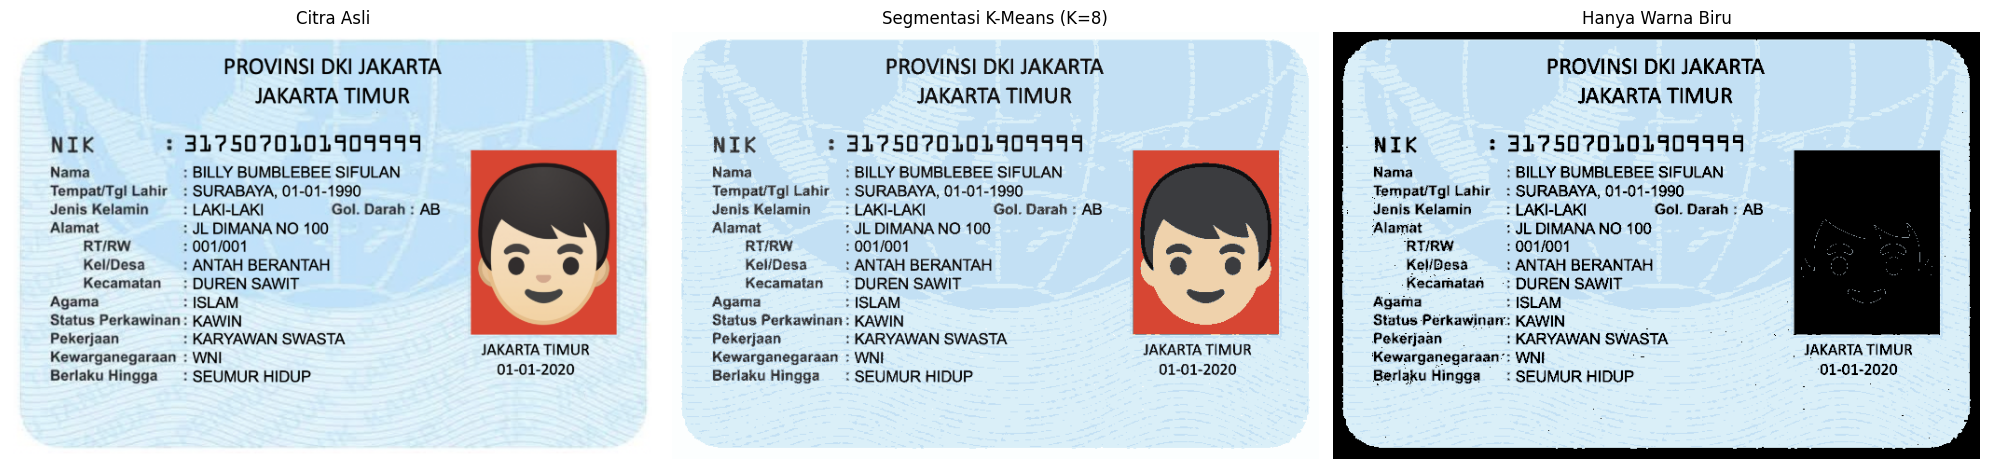

Piksel biru: 247533 dari 317852 (77.9%)


In [17]:
# Hanya warna biru: piksel di luar cluster biru dibuat hitam
mask_biru = np.isin(labels, kelompok_biru).reshape(img_rgb.shape[:2])
hanya_biru = np.zeros_like(img_rgb)
hanya_biru[mask_biru] = segmented_img[mask_biru]

plt.figure(figsize=(20, 5))
tampil = [img_rgb, segmented_img, hanya_biru]
judul = ['Citra Asli', f'Segmentasi K-Means (K={K})', 'Hanya Warna Biru']
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(tampil[i])
    plt.title(judul[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

print(f'Piksel biru: {int(mask_biru.sum())} dari {mask_biru.size} ({100 * mask_biru.mean():.1f}%)')

**Catatan:** jika hasil "hanya warna biru" tidak sesuai (misalnya latar KTP yang biru muda tidak terpilih), periksa kolom `H`, `S`, `V` pada tabel pusat cluster. Latar biru muda memiliki saturasi (S) rendah, sehingga cluster tersebut bisa lolos atau tidak lolos tergantung batas `S >= 25`. Anda dapat mengubah K atau rentang HSV, tetapi untuk tugas gunakan rentang yang diberikan pada soal.

---
**Selesai - Tugas D1 (Individu).**